# FPV conditioned on the orthographic views: masking vs. no masking

This notebook walks through the training step in `new_train_ortho_wan.py` and the idea from its *Ideas to try* note:

> Train FPV conditioned on the other views. During training, give some target views to the model clean and compute the loss only on the noisy ones. At inference, generate top/side/rear first, then FPV with those as conditioning.

There are two ways to implement it, and both are coded here:

* **Option A, masking:** keep the 4 target slots and overwrite some of them with clean latents. A per-view mask removes those slots from the loss.
* **Option B, no masking:** move the clean ortho views into the *context* frames, so FPV is the only target.

Section 7 shows they feed the model **exactly the same tensor**. Everything runs in about six minutes on a GPU (much longer on CPU). A ~3M-parameter `ToyDiT` replaces Wan and has the same call signature, and a toy "world" replaces the games. In the toy, FPV is fully determined by the ortho views at the same timestep, so you can see the conditioning work.

**Contents**
1. Flow matching recap (the equations behind `train_ortho_flow_step`)
2. The toy world
3. The toy DiT (a stand-in for `WanTransformer3DModel`)
4. The current joint training step and sampler
5. Option A: masking
6. Option B: no masking
7. Why A and B are the same computation
8. Training three toy models
9. Evaluation: joint vs. two-stage vs. oracle
10. Three arms: single vs. FPV→all vs. ortho
11. Dropping it into `new_train_ortho_wan.py`
12. Tangle: leave-one-out training and refinement

In [1]:
import math, random
from collections import defaultdict
from types import SimpleNamespace

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0); random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

VIEW_NAMES = ["Top", "Side", "Rear", "3D_FPV"]  # same order as the training script: FPV is always the last view
FPV_IDX = 3
V = 4                                           # views per timestep
C, H, W = 4, 4, 4                               # toy latent size (Wan: C=16, h=w=12 for 96x96 frames)
print("device:", device)

device: cuda


## 0. Shapes

In the training script, each view is encoded by the Wan VAE as a **single-frame video**, so the VAE's frame axis becomes the *view* axis:

```
views (B, 4, 3, 96, 96)  --encode_views_to_latents-->  latents (B, C=16, 4, 12, 12)
                                                                 ^ axis 2 = Top, Side, Rear, FPV
```

`train_ortho_flow_step` concatenates context and target **along that axis**, so the DiT sees one 8-frame "video":

```
frame:     0     1     2     3   |   4      5      6      7
         Top   Side  Rear  FPV   |  Top    Side   Rear   FPV
         ---- views_t (clean) -- | ---- views_{t+1} (noisy at tau) ----
loss:                            |   yes    yes    yes    yes
```

### The three arms

Each arm changes only which views go into the context and which views are targets. FPV's loss term always has weight 1, so `PSNR/FPV` is comparable across arms.

**single** (`--views fpv`): sees FPV, predicts FPV
```
frame:     0    |   1
          FPV   |  FPV
        views_t | views_{t+1} (noisy at tau)
loss:           |  yes
```

**FPV→all** (`--views all --context_views fpv`): sees FPV, predicts all four views
```
frame:     0    |   1      2      3      4
          FPV   |  Top    Side   Rear   FPV
        views_t | ---- views_{t+1} (noisy at tau) ----
loss:           |   yes    yes    yes    yes
```

**ortho** (`--views all`): sees all four views, predicts all four views
```
frame:     0     1     2     3   |   4      5      6      7
         Top   Side  Rear  FPV   |  Top    Side   Rear   FPV
         ---- views_t (clean) -- | ---- views_{t+1} (noisy at tau) ----
loss:                            |   yes    yes    yes    yes
```

* **single vs. FPV→all:** does *predicting* the ortho views (as auxiliary targets) help FPV?
* **FPV→all vs. ortho:** does *seeing* the ortho views (as context) help FPV?

FPV→all needs only FPV at inference, as single does. That's the realistic setting: a real game only gives you the FPV frame. Section 10 trains all three arms on the toy.

Wan's 3D RoPE tells the model *which frame is which*: context vs. target, and which view. There is **one timestep per sample** (`timestep` has shape `(B,)`), so the clean context frames carry the noisy targets' timestep too. The model tells them apart by position and content. Both options below rely on exactly that.

## 1. Flow matching recap

Let $x_0$ be a clean target latent (the views at $t+1$) and $\epsilon \sim \mathcal N(0, I)$. Rectified flow interpolates on a straight line, with $\tau = 0$ clean and $\tau = 1$ pure noise:

$$x_\tau = (1-\tau)\,x_0 + \tau\,\epsilon .$$

The **velocity** along that line is constant:

$$v = \frac{d x_\tau}{d\tau} = \epsilon - x_0 \qquad\text{(`target_velocity = noise - latents_next`)}.$$

The network $v_\theta(x_\tau, \tau, c)$ is regressed onto it, where $c$ is the conditioning (context frames and prompt):

$$\mathcal L = \mathbb E_{x_0,\epsilon,\tau}\;\big\| v_\theta(x_\tau,\tau,c) - (\epsilon - x_0)\big\|^2 .$$

The script sums one MSE per view, so each view's term has weight 1: $\mathcal L = \sum_{v} \operatorname{MSE}_v$.

**Timestep sampling (step 1).** A shifted logit-normal, which puts more mass on high noise:

$$u\sim\mathcal N(0,1),\quad \tau_0 = \sigma(u),\quad \tau = \frac{s\,\tau_0}{1+(s-1)\,\tau_0},\quad s = 3 .$$

**Context noise (step 2).** The context is slightly corrupted so the model tolerates its own imperfect outputs in an autoregressive rollout:

$$\tilde c = (1-\tau_c)\,c + \tau_c\,\eta,\qquad \tau_c\sim\mathcal U(0,\,0.15),\ \eta\sim\mathcal N(0,I).$$

**One-step clean estimate** (used for student forcing): $\hat x_0 = x_\tau - \tau\, v_\theta$.

**Sampling (Euler, `predict_next_view_latents`).** Start from $x_1=\epsilon$ and step down a shifted grid $1=\tau_0>\tau_1>\dots>\tau_K=0$:

$$x_{\tau_{k+1}} = x_{\tau_k} - (\tau_k-\tau_{k+1})\; v_\theta(x_{\tau_k}, \tau_k, c).$$

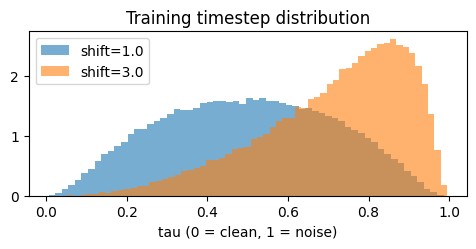

In [2]:
def sample_tau(b, shift=3.0, device=device):
    # Shifted logit-normal tau in (0, 1): step 1 of train_ortho_flow_step
    u = torch.randn(b, device=device, dtype=torch.float32)
    tau = torch.sigmoid(u)
    tau = (shift * tau) / (1.0 + (shift - 1.0) * tau)
    return tau.clamp(1e-4, 1.0 - 1e-4)

plt.figure(figsize=(5, 2.6))
for s in (1.0, 3.0):
    plt.hist(sample_tau(100_000, s).cpu(), bins=60, alpha=0.6, density=True, label=f"shift={s}")
plt.xlabel("tau (0 = clean, 1 = noise)"); plt.legend(); plt.title("Training timestep distribution"); plt.tight_layout(); plt.show()

## 2. The toy world

The toy mirrors the hypothesis behind the idea. **The ortho views at $t+1$ are a layout that pins down the FPV frame at $t+1$.**

* The ortho views at $t+1$ depend on the ortho views at $t$, through a fixed mixing $M$ across the three views (a random rotation of their stacked channels), plus an unpredictable part $z$ (think of the next action's outcome):
  $o_{t+1} = 0.6\,M(o_t) + 0.8\,z$.
* FPV is a fixed "rendering" of the layout at the same timestep: $f_{t+1} = R(o_{t+1})$, with $R$ a fixed random linear map.

FPV is a 4-channel projection of the 12 ortho channels, so it drops information. Because of $M$, the information it drops matters for the next step. FPV$_t$ alone therefore predicts FPV$_{t+1}$ worse than all four views do; this is the effect the arms in section 10 measure. Without $M$, the toy would be linear in FPV and seeing the ortho views couldn't help.

So $p(f_{t+1}\mid V_t)$ is broad, because it inherits all of $z$. But $p(f_{t+1}\mid o_{t+1}, V_t)$ is a point mass. A model that sees $o_{t+1}$ should be able to drive the FPV loss to almost zero.

In [3]:
_g = torch.Generator().manual_seed(1234)
RENDER = (torch.randn(C, 3 * C, generator=_g) / math.sqrt(3 * C)).to(device)  # fixed "renderer" R
MIX = torch.linalg.qr(torch.randn(3 * C, 3 * C, generator=_g))[0].to(device)  # fixed rotation M across the 3 views

def mix_views(ortho):
    # (B, C, 3, H, W) -> same shape: rotates each pixel's 12 stacked ortho channels by M
    b = ortho.shape[0]
    flat = ortho.permute(0, 3, 4, 2, 1).reshape(b, H, W, 3 * C) @ MIX.T
    return flat.reshape(b, H, W, 3, C).permute(0, 4, 3, 1, 2)

def render_fpv(ortho):
    # ortho: (B, C, 3, H, W) -> FPV (B, C, 1, H, W): a fixed per-pixel mix of the 3 ortho views' channels
    b = ortho.shape[0]
    flat = ortho.permute(0, 3, 4, 2, 1).reshape(b, H, W, 3 * C)
    return (flat @ RENDER.T).permute(0, 3, 1, 2).unsqueeze(2)

def make_batch(b):
    # Returns views_t, views_next as latents (B, C, V, H, W), view order Top, Side, Rear, FPV
    ortho_t = torch.randn(b, C, 3, H, W, device=device)
    z = torch.randn(b, C, 3, H, W, device=device)              # what views_t can't tell you about t+1
    ortho_next = 0.6 * mix_views(ortho_t) + 0.8 * z
    views_t = torch.cat([ortho_t, render_fpv(ortho_t)], dim=2)
    views_next = torch.cat([ortho_next, render_fpv(ortho_next)], dim=2)
    return views_t, views_next

def cond_var(y, x):
    # Residual variance of the best linear predictor of y from x. The toy is linear-Gaussian, so this is exactly Var(y | x)
    X = torch.cat([x.flatten(1), torch.ones(len(x), 1, device=x.device)], dim=1).cpu()
    Y = y.flatten(1).cpu()
    return (Y - X @ torch.linalg.lstsq(X, Y).solution).var().item()

views_t, views_next = make_batch(20000)
print("views_t", tuple(views_t.shape), "| per-view std:", views_next.std(dim=(0, 1, 3, 4)).cpu().numpy().round(2))
print(f"Var(FPV_t+1 | all views_t) = {cond_var(views_next[:, :, 3:], views_t):.3f}")
print(f"Var(FPV_t+1 | FPV_t only)  = {cond_var(views_next[:, :, 3:], views_t[:, :, 3:]):.3f}   <- FPV alone knows less")
print("An ideal sampler's FPV MSE to GT is 2x the conditional variance of its context")

views_t (20000, 4, 4, 4, 4) | per-view std: [1.   1.   1.   0.87]
Var(FPV_t+1 | all views_t) = 0.482
Var(FPV_t+1 | FPV_t only)  = 0.666   <- FPV alone knows less
An ideal sampler's FPV MSE to GT is 2x the conditional variance of its context


## 3. Toy DiT

`ToyDiT` has the same call as `WanTransformer3DModel`: `transformer(hidden_states=(B, C, F, H, W), timestep=(B,), encoder_hidden_states=...).sample`. Each frame is one token; Wan uses 2×2 patches, so 36 tokens per frame. A learned frame embedding plays the role of the 3D RoPE. The prompt embedding is ignored here: it's identical in both options, so it doesn't affect the comparison.

In [4]:
class ToyDiT(nn.Module):
    def __init__(self, max_frames=2 * V, d=256, layers=4):
        super().__init__()
        self.inp = nn.Linear(C * H * W, d)
        self.pos = nn.Parameter(0.02 * torch.randn(max_frames, d))  # frame position, stands in for Wan's RoPE
        self.t_emb = nn.Sequential(nn.Linear(1, d), nn.SiLU(), nn.Linear(d, d))
        layer = nn.TransformerEncoderLayer(d, nhead=4, dim_feedforward=4 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.out = nn.Linear(d, C * H * W)

    @property
    def dtype(self):
        return next(self.parameters()).dtype

    def forward(self, hidden_states, timestep, encoder_hidden_states=None):
        b, c, f, h, w = hidden_states.shape
        x = hidden_states.permute(0, 2, 1, 3, 4).reshape(b, f, c * h * w)
        x = self.inp(x) + self.pos[:f] + self.t_emb((timestep.float() / 1000.0).view(b, 1, 1))  # ONE timestep per sample
        x = self.out(self.blocks(x))
        return SimpleNamespace(sample=x.view(b, f, c, h, w).permute(0, 2, 1, 3, 4))

print(f"ToyDiT params: {sum(p.numel() for p in ToyDiT().parameters()) / 1e6:.2f}M")

ToyDiT params: 3.26M


## 4. The current joint training step

This is `train_ortho_flow_step` from the script, unchanged apart from using `sample_tau`. It models the **joint** distribution of all four views at $t+1$:

$$p_\theta(o_{t+1}, f_{t+1} \mid V_t)$$

All four targets are noised with the same $\tau$ and denoised together. Nothing is conditioned on anything else at $t+1$; the views can only coordinate through attention while they denoise. The script's docstring says it learns $P(\text{3D}_{t+1}\mid \text{top}_{t+1},\dots)$, but this joint step doesn't do that.

In [5]:
def train_ortho_flow_step(transformer, latents_t, latents_next, prompt_embeds=None, shift=3.0, ctx_noise_max=0.15):
    b, c, num_views, h, w = latents_next.shape

    # 1. Shifted logit-normal flow-matching timestep tau in (0, 1)
    tau = sample_tau(b, shift, latents_next.device)
    tau_exp = tau.view(b, 1, 1, 1, 1)

    # 2. Context noise augmentation on conditioning views `latents_t`
    latents_t_fp32 = latents_t.float()
    tau_ctx = torch.rand((b, 1, 1, 1, 1), device=latents_t.device, dtype=torch.float32) * ctx_noise_max
    ctx_noise = torch.randn_like(latents_t_fp32)
    cond_latents_t = ((1.0 - tau_ctx) * latents_t_fp32 + tau_ctx * ctx_noise).to(dtype=transformer.dtype)

    # 3. Noise all target views at t+1 simultaneously
    latents_next_fp32 = latents_next.float()
    noise = torch.randn_like(latents_next_fp32)
    noisy_latents_next_fp32 = (1.0 - tau_exp) * latents_next_fp32 + tau_exp * noise
    noisy_latents_next = noisy_latents_next_fp32.to(dtype=transformer.dtype)

    # 4. Concatenate conditioning views (frames 0:V) and noisy target views (frames V:2V)
    combined_latents = torch.cat([cond_latents_t, noisy_latents_next], dim=2)

    # 5. Ground truth velocity: v_target = noise - x_0
    target_velocity = noise - latents_next_fp32

    # 6. DiT forward pass
    timesteps = (tau * 1000.0).to(dtype=transformer.dtype)
    model_pred = transformer(hidden_states=combined_latents, timestep=timesteps, encoder_hidden_states=prompt_embeds).sample

    # 7. Supervise target views at t+1 (indices num_views:2*num_views)
    pred_velocity = model_pred[:, :, num_views : 2 * num_views].float()
    per_view_losses = [F.mse_loss(pred_velocity[:, :, idx], target_velocity[:, :, idx]) for idx in range(num_views)]
    loss = sum(per_view_losses)

    # Reconstruct 1-step denoised prediction for student forcing: x_0_hat = x_tau - tau * v_pred
    with torch.no_grad():
        pred_x0 = (noisy_latents_next_fp32 - tau_exp * pred_velocity.detach()).clamp(-6.0, 6.0)
        confidence = (1.0 - tau_exp).clamp(0.2, 1.0)
        rollout_latent = (confidence * pred_x0 + (1.0 - confidence) * latents_next_fp32).to(dtype=transformer.dtype)
    return loss, [l.item() for l in per_view_losses], rollout_latent


@torch.no_grad()
def predict_next_view_latents(transformer, latents_t, prompt_embeds=None, steps=20, shift=3.0):
    # The script's sampler: jointly denoises the V views at t+1 with reverse Euler
    b, c, num_views, h, w = latents_t.shape
    latents_t = latents_t.to(dtype=transformer.dtype)
    x_tau = torch.randn((b, c, num_views, h, w), device=latents_t.device, dtype=torch.float32)
    sigmas = torch.linspace(1.0, 0.0, steps + 1, device=latents_t.device, dtype=torch.float32)
    sigmas = (shift * sigmas) / (1.0 + (shift - 1.0) * sigmas)
    for step_i in range(steps):
        sigma_curr, sigma_next = sigmas[step_i], sigmas[step_i + 1]
        t_tensor = torch.full((b,), sigma_curr * 1000.0, device=latents_t.device, dtype=transformer.dtype)
        combined = torch.cat([latents_t, x_tau.to(dtype=transformer.dtype)], dim=2)
        pred_velocity = transformer(hidden_states=combined, timestep=t_tensor,
                                    encoder_hidden_states=prompt_embeds).sample[:, :, num_views : 2 * num_views].float()
        x_tau = x_tau - (sigma_curr - sigma_next) * pred_velocity
    return x_tau.to(dtype=transformer.dtype)

## 5. Option A: masking

Two-stage generation uses this factorization:

$$p(o_{t+1}, f_{t+1}\mid V_t) \;=\; \underbrace{p(o_{t+1}\mid V_t)}_{\text{stage 1}}\;\underbrace{p(f_{t+1}\mid o_{t+1}, V_t)}_{\text{stage 2}} .$$

Each sample gets a mask $m_{b,v}\in\{0,1\}$ ($1$ = view $v$ is given clean). With probability `fpv_cond_prob`, the three ortho slots are clean; otherwise the sample is joint, as before. **FPV is never clean.**

* **Model input:** a clean slot holds $\tilde x_0 = (1-\tau_c)\,x_0 + \tau_c\,\eta$. It gets the same context noise as `views_t`, because at inference it will be a *generated* view. A noisy slot holds $x_\tau$, as before.
* **Loss:** only noisy slots count:

$$\mathcal L = \sum_{v} \frac{1}{B}\sum_{b} (1-m_{b,v})\;\operatorname{MSE}_{b,v},\qquad \operatorname{MSE}_{b,v}=\tfrac{1}{CHW}\big\|v_\theta - (\epsilon-x_0)\big\|^2_{b,v}.$$

With $m\equiv 0$, this is exactly the current loss. The FPV term never changes because FPV is always noisy.

Layout of a conditioned sample:
```
frame:     0     1     2     3   |   4      5      6      7
         ------ views_t -------  | Top    Side   Rear   FPV
                                 | clean  clean  clean  noisy
loss:                            |   -      -      -     yes
```

**Sampler:** run Euler as usual, but before every model call, overwrite the clean slots with the given latents. This is inpainting along the view axis. The `# NEW` comments mark every line that differs from the script.

In [6]:
def sample_clean_target_mask(b, num_views, fpv_cond_prob, device):                    # NEW
    # (B, V) bool, True = target view given to the model clean. FPV (last view) is always noisy.
    mask = torch.zeros(b, num_views, dtype=torch.bool, device=device)
    if num_views > 1 and fpv_cond_prob > 0:
        mask[:, :-1] = torch.rand(b, 1, device=device) < fpv_cond_prob
    return mask


def train_ortho_flow_step_masked(transformer, latents_t, latents_next, prompt_embeds=None, shift=3.0,
                                 ctx_noise_max=0.15, fpv_cond_prob=0.5):              # NEW arg
    b, c, num_views, h, w = latents_next.shape

    tau = sample_tau(b, shift, latents_next.device)
    tau_exp = tau.view(b, 1, 1, 1, 1)

    latents_t_fp32 = latents_t.float()
    tau_ctx = torch.rand((b, 1, 1, 1, 1), device=latents_t.device, dtype=torch.float32) * ctx_noise_max
    ctx_noise = torch.randn_like(latents_t_fp32)
    cond_latents_t = ((1.0 - tau_ctx) * latents_t_fp32 + tau_ctx * ctx_noise).to(dtype=transformer.dtype)

    latents_next_fp32 = latents_next.float()
    noise = torch.randn_like(latents_next_fp32)
    noisy_latents_next_fp32 = (1.0 - tau_exp) * latents_next_fp32 + tau_exp * noise

    # 3b. Some target views go in clean, with the same context noise as views_t (at inference they are generated)  # NEW
    clean_mask = sample_clean_target_mask(b, num_views, fpv_cond_prob, latents_next.device)                       # NEW
    m = clean_mask.view(b, 1, num_views, 1, 1)                                                                     # NEW
    clean_next_fp32 = (1.0 - tau_ctx) * latents_next_fp32 + tau_ctx * torch.randn_like(latents_next_fp32)         # NEW
    noisy_latents_next = torch.where(m, clean_next_fp32, noisy_latents_next_fp32).to(dtype=transformer.dtype)     # NEW

    combined_latents = torch.cat([cond_latents_t, noisy_latents_next], dim=2)
    target_velocity = noise - latents_next_fp32
    timesteps = (tau * 1000.0).to(dtype=transformer.dtype)
    model_pred = transformer(hidden_states=combined_latents, timestep=timesteps, encoder_hidden_states=prompt_embeds).sample
    pred_velocity = model_pred[:, :, num_views : 2 * num_views].float()

    # 7. Loss only on the noisy views                                                  # NEW
    noisy = (~clean_mask).float()                                                       # NEW (B, V)
    mse = ((pred_velocity - target_velocity) ** 2).mean(dim=(1, 3, 4))                  # NEW (B, V)
    loss = (mse * noisy).mean(0).sum()                                                  # NEW

    # Logs: ortho views over the samples where they were noisy; FPV split by mode       # NEW
    logs = {}
    with torch.no_grad():
        cond = clean_mask[:, 0]
        for v in range(num_views - 1):
            if (~cond).any():
                logs[f"Loss_{VIEW_NAMES[v]}"] = mse[~cond, v].mean().item()
        if (~cond).any():
            logs["Loss_FPV_joint"] = mse[~cond, -1].mean().item()
        if cond.any():
            logs["Loss_FPV_cond"] = mse[cond, -1].mean().item()

        pred_x0 = (noisy_latents_next_fp32 - tau_exp * pred_velocity.detach()).clamp(-6.0, 6.0)
        confidence = (1.0 - tau_exp).clamp(0.2, 1.0)
        rollout_latent = confidence * pred_x0 + (1.0 - confidence) * latents_next_fp32
        # pred_x0 is meaningless for views that went in clean: pass on what was fed in   # NEW
        rollout_latent = torch.where(m, clean_next_fp32, rollout_latent).to(dtype=transformer.dtype)  # NEW
    return loss, logs, rollout_latent


@torch.no_grad()
def predict_next_view_latents_masked(transformer, latents_t, prompt_embeds=None, steps=20, shift=3.0,
                                     clean_next=None, clean_mask=None):                 # NEW args
    b, c, num_views, h, w = latents_t.shape
    latents_t = latents_t.to(dtype=transformer.dtype)
    x_tau = torch.randn((b, c, num_views, h, w), device=latents_t.device, dtype=torch.float32)
    m = None if clean_next is None else clean_mask.view(b, 1, num_views, 1, 1)           # NEW
    sigmas = torch.linspace(1.0, 0.0, steps + 1, device=latents_t.device, dtype=torch.float32)
    sigmas = (shift * sigmas) / (1.0 + (shift - 1.0) * sigmas)
    for step_i in range(steps):
        sigma_curr, sigma_next = sigmas[step_i], sigmas[step_i + 1]
        t_tensor = torch.full((b,), sigma_curr * 1000.0, device=latents_t.device, dtype=transformer.dtype)
        x_in = x_tau if m is None else torch.where(m, clean_next.float(), x_tau)          # NEW
        combined = torch.cat([latents_t, x_in.to(dtype=transformer.dtype)], dim=2)
        pred_velocity = transformer(hidden_states=combined, timestep=t_tensor,
                                    encoder_hidden_states=prompt_embeds).sample[:, :, num_views : 2 * num_views].float()
        x_tau = x_tau - (sigma_curr - sigma_next) * pred_velocity
    if m is not None:
        x_tau = torch.where(m, clean_next.float(), x_tau)                                  # NEW
    return x_tau.to(dtype=transformer.dtype)


@torch.no_grad()
def predict_two_stage_masked(transformer, latents_t, prompt_embeds=None, steps=20, shift=3.0, ortho_next=None):
    # Stage 1: joint denoise, keep top/side/rear. Stage 2: FPV with those as clean slots.
    # Pass ortho_next (B, C, 3, h, w), e.g. GT latents, to skip stage 1 (the oracle).
    b, c, num_views, h, w = latents_t.shape
    if ortho_next is None:
        ortho_next = predict_next_view_latents_masked(transformer, latents_t, prompt_embeds, steps, shift)[:, :, :-1]
    clean_next = torch.cat([ortho_next, torch.zeros_like(ortho_next[:, :, :1])], dim=2)  # FPV slot is never read
    mask = torch.zeros(b, num_views, dtype=torch.bool, device=latents_t.device)
    mask[:, :-1] = True
    return predict_next_view_latents_masked(transformer, latents_t, prompt_embeds, steps, shift,
                                            clean_next=clean_next, clean_mask=mask)

**Check:** with `fpv_cond_prob=0`, the masked step is the current step. Same seed, same random draws, so the loss is identical. The extra `randn` for the clean slots is drawn *after* everything the original step draws.

In [7]:
model = ToyDiT().to(device)
vt, vn = make_batch(16)
torch.manual_seed(7); loss_orig, _, _ = train_ortho_flow_step(model, vt, vn)
torch.manual_seed(7); loss_mask, _, _ = train_ortho_flow_step_masked(model, vt, vn, fpv_cond_prob=0.0)
print(f"current step: {loss_orig.item():.6f}   masked step (p=0): {loss_mask.item():.6f}   equal: {torch.allclose(loss_orig, loss_mask)}")

current step: 9.867964   masked step (p=0): 9.867964   equal: True


## 6. Option B: no masking

Instead of keeping clean views in target slots, **put them in the context**. The model already knows how to read clean frames there:

| | context frames (clean + ctx noise) | target frames (noisy, supervised) |
|---|---|---|
| joint (stage 1) | `views_t` (4) | Top, Side, Rear, FPV at $t+1$ (4) |
| FPV-conditioned (stage 2) | `views_t` (4) + Top, Side, Rear at $t+1$ (3) | FPV at $t+1$ (1) |

The step function needs **one change**: supervise the *last* `num_targets` frames instead of frames `[V:2V]`. With 4 context and 4 target frames, `[-4:]` and `[4:8]` are the same slice, so joint training is untouched. The same one-line change goes into the sampler.

Which task to train is chosen **per batch** (in the script, per trajectory) with probability `fpv_cond_prob`, rather than per sample.

In [8]:
def train_flow_step(transformer, latents_t, latents_next, prompt_embeds=None, shift=3.0, ctx_noise_max=0.15):
    # train_ortho_flow_step with ONE change: latents_t may hold more frames than latents_next,
    # and the supervised frames are the LAST num_targets frames.
    b, c, num_targets, h, w = latents_next.shape

    tau = sample_tau(b, shift, latents_next.device)
    tau_exp = tau.view(b, 1, 1, 1, 1)

    latents_t_fp32 = latents_t.float()
    tau_ctx = torch.rand((b, 1, 1, 1, 1), device=latents_t.device, dtype=torch.float32) * ctx_noise_max
    ctx_noise = torch.randn_like(latents_t_fp32)
    cond_latents_t = ((1.0 - tau_ctx) * latents_t_fp32 + tau_ctx * ctx_noise).to(dtype=transformer.dtype)

    latents_next_fp32 = latents_next.float()
    noise = torch.randn_like(latents_next_fp32)
    noisy_latents_next_fp32 = (1.0 - tau_exp) * latents_next_fp32 + tau_exp * noise
    noisy_latents_next = noisy_latents_next_fp32.to(dtype=transformer.dtype)

    combined_latents = torch.cat([cond_latents_t, noisy_latents_next], dim=2)
    target_velocity = noise - latents_next_fp32
    timesteps = (tau * 1000.0).to(dtype=transformer.dtype)
    model_pred = transformer(hidden_states=combined_latents, timestep=timesteps, encoder_hidden_states=prompt_embeds).sample

    pred_velocity = model_pred[:, :, -num_targets:].float()                    # NEW (was [num_views : 2 * num_views])
    per_view_losses = [F.mse_loss(pred_velocity[:, :, idx], target_velocity[:, :, idx]) for idx in range(num_targets)]
    loss = sum(per_view_losses)

    with torch.no_grad():
        pred_x0 = (noisy_latents_next_fp32 - tau_exp * pred_velocity.detach()).clamp(-6.0, 6.0)
        confidence = (1.0 - tau_exp).clamp(0.2, 1.0)
        rollout_latent = (confidence * pred_x0 + (1.0 - confidence) * latents_next_fp32).to(dtype=transformer.dtype)
    return loss, [l.item() for l in per_view_losses], rollout_latent


def train_flow_step_nomask(transformer, latents_t, latents_next, prompt_embeds=None, shift=3.0,
                           ctx_noise_max=0.15, fpv_cond_prob=0.5):
    # Option B: per batch, either the joint step or the FPV step with the orthos at t+1 moved into the context
    num_views = latents_next.shape[2]
    if num_views > 1 and random.random() < fpv_cond_prob:
        ortho_next = latents_next[:, :, :-1]
        loss, (fpv_loss,), pred_fpv = train_flow_step(
            transformer,
            torch.cat([latents_t, ortho_next], dim=2),     # orthos at t+1 join the context (get ctx noise too)
            latents_next[:, :, -1:],                       # FPV is the only target
            prompt_embeds, shift, ctx_noise_max,
        )
        return loss, {"Loss_FPV_cond": fpv_loss}, torch.cat([ortho_next, pred_fpv], dim=2)
    loss, per_view, rollout_latent = train_flow_step(transformer, latents_t, latents_next, prompt_embeds, shift, ctx_noise_max)
    logs = {f"Loss_{VIEW_NAMES[v]}": per_view[v] for v in range(num_views - 1)}
    logs["Loss_FPV_joint"] = per_view[-1]
    return loss, logs, rollout_latent


@torch.no_grad()
def predict_next_latents(transformer, latents_t, prompt_embeds=None, steps=20, shift=3.0, num_targets=None):
    # The script's sampler with ONE change: x_tau has num_targets frames, and the prediction is the last num_targets frames
    b, c, num_ctx, h, w = latents_t.shape
    num_targets = num_targets or num_ctx                                                    # NEW
    latents_t = latents_t.to(dtype=transformer.dtype)
    x_tau = torch.randn((b, c, num_targets, h, w), device=latents_t.device, dtype=torch.float32)  # NEW num_targets
    sigmas = torch.linspace(1.0, 0.0, steps + 1, device=latents_t.device, dtype=torch.float32)
    sigmas = (shift * sigmas) / (1.0 + (shift - 1.0) * sigmas)
    for step_i in range(steps):
        sigma_curr, sigma_next = sigmas[step_i], sigmas[step_i + 1]
        t_tensor = torch.full((b,), sigma_curr * 1000.0, device=latents_t.device, dtype=transformer.dtype)
        combined = torch.cat([latents_t, x_tau.to(dtype=transformer.dtype)], dim=2)
        pred_velocity = transformer(hidden_states=combined, timestep=t_tensor,
                                    encoder_hidden_states=prompt_embeds).sample[:, :, -num_targets:].float()  # NEW
        x_tau = x_tau - (sigma_curr - sigma_next) * pred_velocity
    return x_tau.to(dtype=transformer.dtype)


@torch.no_grad()
def predict_two_stage(transformer, latents_t, prompt_embeds=None, steps=20, shift=3.0, ortho_next=None):
    # Stage 1: joint denoise, keep top/side/rear. Stage 2: FPV with those appended to the context.
    # Pass ortho_next (B, C, 3, h, w), e.g. GT latents, to skip stage 1 (the oracle).
    if ortho_next is None:
        ortho_next = predict_next_latents(transformer, latents_t, prompt_embeds, steps, shift)[:, :, :-1]
    ortho_next = ortho_next.to(dtype=transformer.dtype)
    fpv = predict_next_latents(transformer, torch.cat([latents_t, ortho_next], dim=2), prompt_embeds, steps, shift,
                               num_targets=1)
    return torch.cat([ortho_next, fpv], dim=2)

**Check:** on joint inputs, the generalized step is the current step: same seed, same loss.

In [9]:
torch.manual_seed(7); loss_orig, _, _ = train_ortho_flow_step(model, vt, vn)
torch.manual_seed(7); loss_gen, _, _ = train_flow_step(model, vt, vn)
print(f"current step: {loss_orig.item():.6f}   generalized step: {loss_gen.item():.6f}   equal: {torch.allclose(loss_orig, loss_gen)}")

current step: 9.867964   generalized step: 9.867964   equal: True


## 7. Why A and B are the same computation

For an FPV-conditioned sample, build the model input both ways from the **same** $\tau$, $\epsilon$, $\tau_c$ and $\eta$:

* **A:** `[ctx(views_t), where(mask, clean(ortho_{t+1}), noisy(views_{t+1}))]`, giving 8 frames.
* **B:** `[ctx(views_t ++ ortho_{t+1}), noisy(FPV_{t+1})]`, also 8 frames.

Frame for frame these are the same tensor, with the same timestep. So the model output is the same, and the FPV loss is the same. Masking is only bookkeeping: it keeps the target block at 4 frames and zeroes the loss on 3 of them. That has two consequences:

* A model trained with A can be sampled with B's sampler, and vice versa (section 9 does this).
* The real differences are practical. A mixes modes **per sample**; B mixes them **per batch**. A runs the output head on 3 frames whose outputs are thrown away, which costs nothing measurable. B is less code.

In [10]:
b = 8
vt, vn = make_batch(b)
tau = sample_tau(b).view(b, 1, 1, 1, 1)
eps = torch.randn_like(vn)
tau_c = torch.rand(b, 1, 1, 1, 1, device=device) * 0.15
eta = torch.randn(b, C, 2 * V - 1, H, W, device=device)   # context noise for the 7 clean frames

# Option A: 4 context frames + 4 target slots, ortho slots overwritten with clean latents
ctx_A = (1 - tau_c) * vt + tau_c * eta[:, :, :V]
noisy = (1 - tau) * vn + tau * eps
clean = torch.cat([(1 - tau_c) * vn[:, :, :3] + tau_c * eta[:, :, V:], vn[:, :, 3:]], dim=2)  # FPV slot unused
mask = torch.tensor([True, True, True, False], device=device).view(1, 1, V, 1, 1)
input_A = torch.cat([ctx_A, torch.where(mask, clean, noisy)], dim=2)

# Option B: 7 context frames + 1 target frame
ctx_B = (1 - tau_c) * torch.cat([vt, vn[:, :, :3]], dim=2) + tau_c * eta
input_B = torch.cat([ctx_B, noisy[:, :, -1:]], dim=2)

t = tau.view(b) * 1000
fpv_A = model(input_A, t).sample[:, :, -1]
fpv_B = model(input_B, t).sample[:, :, -1]
print("input shapes:", tuple(input_A.shape), tuple(input_B.shape))
print("identical inputs:", torch.equal(input_A, input_B), "| identical FPV predictions:", torch.allclose(fpv_A, fpv_B))

input shapes: (8, 4, 8, 4, 4) (8, 4, 8, 4, 4)
identical inputs: True | identical FPV predictions: True


## 8. Training three toy models

| run | step function | `fpv_cond_prob` |
|---|---|---|
| **joint**: the current script | `train_ortho_flow_step_masked` (equivalent to the current step at p=0) | 0.0 |
| **A**: masking | `train_ortho_flow_step_masked` | 0.5 |
| **B**: no masking | `train_flow_step_nomask` | 0.5 |

All three see the same data stream and start from the same initialization. The `logs` dict holds what would go to TensorBoard as `Train/<key>`. The curve to watch is `Loss_FPV_cond` against `Loss_FPV_joint`: it shows directly how much the ortho views at $t+1$ help FPV.

In [11]:
def train_toy(step_fn, fpv_cond_prob, steps=4000, batch_size=256, lr=3e-4, seed=0):
    torch.manual_seed(seed); random.seed(seed)
    model = ToyDiT().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps, eta_min=lr * 0.1)
    history = defaultdict(list)
    for step in range(steps):
        views_t, views_next = make_batch(batch_size)
        opt.zero_grad(set_to_none=True)
        loss, logs, _ = step_fn(model, views_t, views_next, fpv_cond_prob=fpv_cond_prob)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step(); sched.step()
        for k, v in logs.items():
            history[k].append((step, v))
    return model.eval(), history

runs = {
    "joint (current)": (train_ortho_flow_step_masked, 0.0),
    "A: masking":      (train_ortho_flow_step_masked, 0.5),
    "B: no masking":   (train_flow_step_nomask,       0.5),
}
models, histories = {}, {}
for name, (fn, p) in runs.items():
    models[name], histories[name] = train_toy(fn, p)
    last = {k: sum(v for _, v in h[-200:]) / len(h[-200:]) for k, h in histories[name].items()}
    print(f"{name:16s}", "  ".join(f"{k}={v:.3f}" for k, v in sorted(last.items())))

joint (current)  Loss_FPV_joint=0.797  Loss_Rear=1.118  Loss_Side=1.120  Loss_Top=1.117
A: masking       Loss_FPV_cond=0.192  Loss_FPV_joint=0.836  Loss_Rear=1.147  Loss_Side=1.155  Loss_Top=1.142
B: no masking    Loss_FPV_cond=0.106  Loss_FPV_joint=0.929  Loss_Rear=1.235  Loss_Side=1.225  Loss_Top=1.169


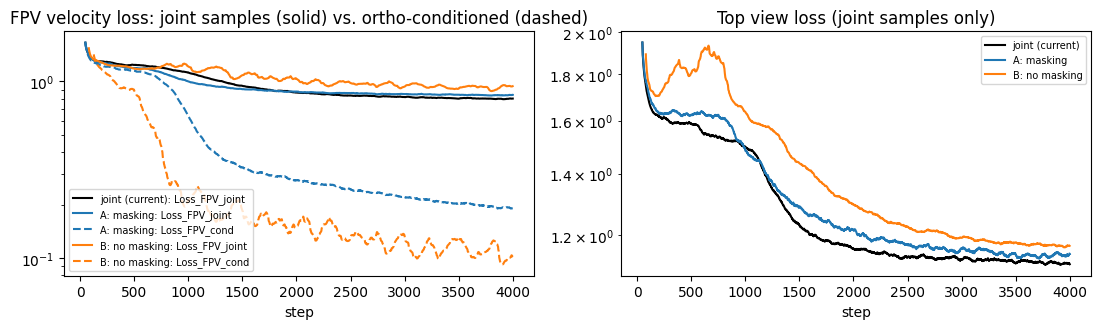

In [12]:
def smooth(points, k=50):
    xs = [s for s, _ in points]; ys = torch.tensor([v for _, v in points])
    ys = torch.nn.functional.avg_pool1d(ys.view(1, 1, -1), k, stride=1).view(-1)
    return xs[k - 1:], ys

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
styles = {"joint (current)": "k", "A: masking": "tab:blue", "B: no masking": "tab:orange"}
for name, hist in histories.items():
    for key, ls in (("Loss_FPV_joint", "-"), ("Loss_FPV_cond", "--")):
        if key in hist:
            ax[0].plot(*smooth(hist[key]), ls, color=styles[name], label=f"{name}: {key}")
    if "Loss_Top" in hist:
        ax[1].plot(*smooth(hist["Loss_Top"]), color=styles[name], label=name)
ax[0].set_title("FPV velocity loss: joint samples (solid) vs. ortho-conditioned (dashed)"); ax[0].set_yscale("log")
ax[1].set_title("Top view loss (joint samples only)"); ax[1].set_yscale("log")
for a in ax: a.set_xlabel("step"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 9. Evaluation: joint vs. two-stage vs. oracle

Three samplers per model, on the same held-out batch:

* **joint**: the current `predict_next_view_latents`; take all 4 views.
* **two-stage**: stage 1 joint, keep the orthos; stage 2 FPV conditioned on them.
* **oracle**: stage 2 with the **ground-truth** orthos at $t+1$. This is the ceiling for the idea. In the real eval, encode `gt_vn[:3]` with `encode_views_to_latents` and pass it as `ortho_next`.

Metrics, all as latent MSE:

* `fpv_vs_gt`: FPV error against ground truth. Because $z$ is unpredictable, *any* correct sampler pays about $2\,\mathrm{Var}(f_{t+1}\mid V_t)$ here unless it is given the true orthos.
* `fpv_vs_its_orthos`: $\|f - R(o)\|^2$, i.e. is the generated FPV consistent with the generated layout? This is what "layout guide" means. It's measurable in the toy because $R$ is known.
* `ortho_vs_gt`: stage-1 quality, for reference.

In [13]:
@torch.no_grad()
def evaluate(model, n=1024, steps=20, seed=123, sampler_two_stage=predict_two_stage):
    torch.manual_seed(seed)
    views_t, gt = make_batch(n)
    gt_ortho, gt_fpv = gt[:, :, :3], gt[:, :, 3:]
    samplers = {
        "joint":     lambda: predict_next_latents(model, views_t, steps=steps),
        "two-stage": lambda: sampler_two_stage(model, views_t, steps=steps),
        "oracle":    lambda: sampler_two_stage(model, views_t, steps=steps, ortho_next=gt_ortho),
    }
    rows = {}
    for name, fn in samplers.items():
        pred = fn().float()
        ortho, fpv = pred[:, :, :3], pred[:, :, 3:]
        rows[name] = (F.mse_loss(fpv, gt_fpv).item(), F.mse_loss(fpv, render_fpv(ortho)).item(), F.mse_loss(ortho, gt_ortho).item())
    return rows

print(f"{'model':16s} {'sampler':10s} {'fpv_vs_gt':>10s} {'fpv_vs_its_orthos':>18s} {'ortho_vs_gt':>12s}")
# An exact sampler draws an independent future: its MSE to GT is 2x the conditional variance given views_t
_vt, _vn = make_batch(20000)
var_ortho, var_fpv = cond_var(_vn[:, :, :3], _vt), cond_var(_vn[:, :, 3:], _vt)
print(f"{'ideal sampler':16s} {'-':10s} {2 * var_fpv:10.3f} {0.0:18.3f} {2 * var_ortho:12.3f}\n")
for mname, model in models.items():
    for sname, (a, b_, c_) in evaluate(model).items():
        print(f"{mname:16s} {sname:10s} {a:10.3f} {b_:18.3f} {c_:12.3f}")
    print()

model            sampler     fpv_vs_gt  fpv_vs_its_orthos  ortho_vs_gt
ideal sampler    -               0.966              0.000        1.267

joint (current)  joint           0.862              0.297        1.098
joint (current)  two-stage       0.841              0.521        1.096
joint (current)  oracle          0.583              0.583        0.000

A: masking       joint           0.867              0.067        1.122
A: masking       two-stage       0.914              0.095        1.119
A: masking       oracle          0.093              0.093        0.000

B: no masking    joint           0.936              0.037        1.222
B: no masking    two-stage       0.973              0.031        1.220
B: no masking    oracle          0.026              0.026        0.000


Section 7's equivalence in practice: the masking-trained model sampled with the **masked** two-stage sampler gives the same numbers, up to sampling noise, as with B's sampler above.

In [14]:
for sname, (a, b_, c_) in evaluate(models["A: masking"], sampler_two_stage=predict_two_stage_masked).items():
    print(f"{'A: masking':16s} {sname:10s} {a:10.3f} {b_:18.3f} {c_:12.3f}   (masked sampler)")

A: masking       joint           0.867              0.067        1.122   (masked sampler)
A: masking       two-stage       0.911              0.094        1.119   (masked sampler)
A: masking       oracle          0.093              0.093        0.000   (masked sampler)


**How to read this** (numbers are from the run saved in this notebook; reruns move them by a few hundredths)

* **The conditional is learned only if you train for it.** Look at the oracle rows. With the true orthos, A and B get FPV error down to 0.09 and 0.03. The joint-only model stays at 0.58, because clean orthos at $t+1$ are out of distribution for it. So this idea needs the `fpv_cond_prob` training; you can't bolt it onto an existing checkpoint at sampling time.
* **Lower MSE to GT is not "better" here.** An *exact* sampler pays about 0.98 on `fpv_vs_gt` and 1.27 on `ortho_vs_gt` (the "ideal" line), because it must commit to one of the possible futures. Every joint row scores *below* that (0.86–0.94 on FPV, 1.10–1.22 on ortho), so joint sampling is under-dispersed: it hedges toward the mean, and MSE rewards hedging. Two-stage commits to a layout in stage 1, renders FPV from it, and lands closer to the ideal. For B it's at 0.97, i.e. *higher* MSE than joint. **PSNR on the real model behaves the same way.** A sharper, more committed FPV can lose PSNR to a blurrier one. Also report LPIPS (`eval_longrollout.py` already computes it) and look at the videos before reading the PSNR.
* **Consistency comes from the conditional training more than from the sampler.** On `fpv_vs_its_orthos`, the joint-only model scores 0.30. Both A and B score under 0.1 with *either* sampler: the FPV-conditioned task teaches the model how the views relate, and joint sampling benefits from that too. Between the two samplers, two-stage was slightly more consistent for B (0.031 vs 0.037) and slightly less for A (0.095 vs 0.067), so don't expect a large difference there.
* **A vs. B.** Their inputs are identical (section 7), so any gap comes from optimization, not from the formulation. B reached a lower conditioned FPV loss here, while its joint-task losses were a bit higher. In earlier runs at shorter training, the ordering flipped depending on whether gradient clipping was on. Treat it as noise. One plausible mechanism: with clipping, A's conditioned-FPV gradient always shares the clipped norm with the joint losses in the same batch.

**What to run on the real model:** the same three rows per checkpoint (joint, two-stage, oracle), compared against the `--views fpv` baseline, with LPIPS next to PSNR. If the oracle doesn't beat the baseline, the ortho views carry no useful layout for FPV in that game, and a better stage 1 won't change that.

## 10. Three arms: single vs. FPV→all vs. ortho

The arms from section 0 differ only in which views are context and which are targets:

| arm | context | targets | flag |
|---|---|---|---|
| single | FPV$_t$ | FPV$_{t+1}$ | `--views fpv` |
| FPV→all | FPV$_t$ | all 4 at $t+1$ | `--views all --context_views fpv` |
| ortho | all 4 at $t$ | all 4 at $t+1$ | `--views all` |

All three use section 6's generalized step, `train_flow_step`, which supervises the last `num_targets` frames. That's what lets the context be shorter than the target (FPV→all: 1 context frame, 4 targets). Samplers use `predict_next_latents(..., num_targets=len(targets))`; FPV is the last predicted frame in every arm.

Each arm's best possible FPV error is set by what its context knows: $2\,\mathrm{Var}(f_{t+1}\mid\text{context})$, computed exactly with `cond_var`. Single and FPV→all share a context, so they share a floor. Only predicting more views can separate them.

In [15]:
ARMS = {  # name: (context view indices, target view indices); FPV is always the last target
    "single":  ((FPV_IDX,), (FPV_IDX,)),
    "FPV->all": ((FPV_IDX,), (0, 1, 2, 3)),
    "ortho":   ((0, 1, 2, 3), (0, 1, 2, 3)),
}

def arm_step(ctx_idx, tgt_idx):
    # Section 6's generalized step on this arm's context/target views (in the script: the views_t / views_next_seq slicing in main)
    def step(transformer, views_t, views_next, fpv_cond_prob=0.0):
        loss, per_view, _ = train_flow_step(transformer, views_t[:, :, list(ctx_idx)], views_next[:, :, list(tgt_idx)])
        return loss, {f"Loss_{VIEW_NAMES[i]}": l for i, l in zip(tgt_idx, per_view)}, None
    return step

arm_models, arm_hist = {}, {}
for name, (ctx, tgt) in ARMS.items():
    arm_models[name], arm_hist[name] = train_toy(arm_step(ctx, tgt), 0.0)
    h = arm_hist[name]["Loss_3D_FPV"]
    print(f"{name:9s} context={len(ctx)} frame(s), targets={len(tgt)}   final FPV velocity loss = {sum(v for _, v in h[-200:]) / 200:.3f}")

single    context=1 frame(s), targets=1   final FPV velocity loss = 1.060
FPV->all  context=1 frame(s), targets=4   final FPV velocity loss = 0.951
ortho     context=4 frame(s), targets=4   final FPV velocity loss = 0.784


arm        fpv_vs_gt  ideal (2*Var)  ortho_vs_gt
single         1.170          1.335            -
FPV->all       1.205          1.335        1.558
ortho          0.847          0.964        1.093


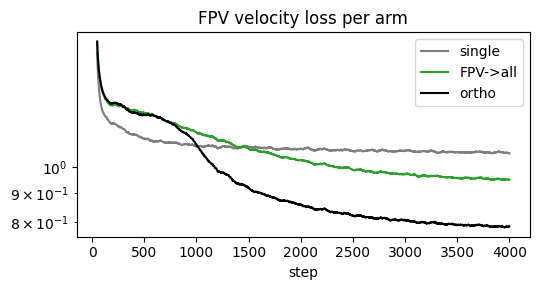

In [16]:
@torch.no_grad()
def evaluate_arms(n=1024, steps=20, seed=123):
    torch.manual_seed(seed)
    views_t, gt = make_batch(n)
    _vt, _vn = make_batch(20000)
    print(f"{'arm':9s} {'fpv_vs_gt':>10s} {'ideal (2*Var)':>14s} {'ortho_vs_gt':>12s}")
    for name, (ctx, tgt) in ARMS.items():
        pred = predict_next_latents(arm_models[name], views_t[:, :, list(ctx)], steps=steps, num_targets=len(tgt)).float()
        ideal = 2 * cond_var(_vn[:, :, 3:], _vt[:, :, list(ctx)])
        ortho = f"{F.mse_loss(pred[:, :, :3], gt[:, :, :3]).item():12.3f}" if len(tgt) == V else f"{'-':>12s}"
        print(f"{name:9s} {F.mse_loss(pred[:, :, -1:], gt[:, :, 3:]).item():10.3f} {ideal:14.3f} {ortho}")

evaluate_arms()

plt.figure(figsize=(5.5, 3))
for name, color in zip(ARMS, ("tab:gray", "tab:green", "k")):
    plt.plot(*smooth(arm_hist[name]["Loss_3D_FPV"]), color=color, label=name)
plt.yscale("log"); plt.xlabel("step"); plt.title("FPV velocity loss per arm"); plt.legend(); plt.tight_layout(); plt.show()

**How to read this**

* **Seeing the ortho views helps (FPV→all vs. ortho).** Ortho's FPV error is 0.85, vs. 1.21 for FPV→all, and its ideal floor is lower too (0.96 vs. 1.34). FPV$_t$ is a lossy projection of the layout, so the ortho views at $t$ carry information about $t+1$ that FPV alone can't recover. In the toy this holds by construction (the mixing $M$). On the real games, it's exactly the question your FPV-only vs. multi-view comparison answers.
* **Predicting the ortho views didn't help here (single vs. FPV→all).** Both arms share a context, so they share the ideal (1.34). Their sampled FPV errors are within noise of each other (1.17 vs. 1.21), and both are below the ideal: the same under-dispersion as in section 9. Any benefit from auxiliary targets comes through better learned features when data or model capacity is limited. A toy with unlimited fresh samples can't show that; the real games can.
* **Don't compare `Train/Loss_3D_FPV` across arms with different targets.** FPV→all's training FPV loss is *lower* than single's (0.95 vs. 1.06), yet its samples are no better. When views are denoised together, the noisy ortho targets at the same $\tau$ are extra noisy measurements of the same scene, so they lower FPV's velocity loss without improving the sample. The ortho arm's training loss gets the same boost. Compare arms on rollout metrics, never on training loss.

**On the real model:** run all three arms with the same seed and data, and compare `Validation/<env>/PSNR/FPV` (plus LPIPS) over the long rollout in `eval_longrollout.py`.

## 11. Dropping it into `new_train_ortho_wan.py`

Both options are opt-in behind a new flag. With `--fpv_cond_prob 0` (the default) and with `--views fpv`, training is exactly what it is today; sections 5 and 6 checked this numerically. Line numbers refer to the current working tree.

### Option B: no masking (recommended: about 15 lines)

**1. `train_ortho_flow_step`, line 159**. Supervise the last `num_views` frames (`num_views` is the number of *target* frames, from `latents_next.shape`):
```python
    pred_velocity = model_pred[:, :, -num_views:].float()
```

**2. `train_ortho_trajectory_step`, line 175.** Add `fpv_cond_prob=0.0`, pick a mode once per trajectory, and switch the call at line 204:
```python
    fpv_cond = num_views > 1 and random.random() < fpv_cond_prob   # one mode for the whole trajectory
    avg_per_view = None
    for s in range(seq_len):
        ...
        if fpv_cond:
            ortho_next = target_latents[:, :, :-1]
            step_loss, step_view_losses, pred_fpv = train_ortho_flow_step(
                transformer=transformer,
                latents_t=torch.cat([curr_latents, ortho_next], dim=2),   # orthos at t+1 join the context
                latents_next=target_latents[:, :, -1:],                    # FPV is the only target
                prompt_embeds=prompt_embeds, shift=shift, ctx_noise_max=ctx_noise_max,
            )
            pred_next_latents = torch.cat([ortho_next, pred_fpv], dim=2)   # context for step s+1
        else:
            step_loss, step_view_losses, pred_next_latents = train_ortho_flow_step(...)  # unchanged
        if avg_per_view is None:
            avg_per_view = [0.0] * len(step_view_losses)                   # 1 entry (FPV) or V entries
        ...
    return total_loss, avg_per_view, fpv_cond
```

**3. `main`, around line 655.** Pass `fpv_cond_prob=args.fpv_cond_prob` and split the logging. `per_view_losses[-1]` is still FPV, so the progress bar is unchanged:
```python
            loss, per_view_losses, fpv_cond = train_ortho_trajectory_step(..., fpv_cond_prob=args.fpv_cond_prob)
            ...
            if fpv_cond:
                writer.add_scalar("Train/Loss_3D_FPV_cond", per_view_losses[-1], global_step)
            else:
                for v_idx, v_name in enumerate(view_names):
                    writer.add_scalar(f"Train/Loss_{v_name}", per_view_losses[v_idx], global_step)
```
`Train/Loss` now mixes two tasks, so compare `Train/Loss_3D_FPV` (joint) against `Train/Loss_3D_FPV_cond` instead.

**4. `predict_next_view_latents`, lines 236/248/266.** Add `num_targets=None`, size `x_tau` with it, and slice `.sample[:, :, -num_targets:]`. Copy `predict_two_stage` from section 6 underneath, renaming `predict_next_latents` → `predict_next_view_latents`.

**5. `autoregressive_rollout`, line 332, and `evaluate_and_log_videos`.** Thread a `two_stage=False` argument through both and call `predict_two_stage(...)` when it's set. `main` passes `two_stage=args.fpv_cond_prob > 0 and len(view_idx) > 1`. Optionally log the oracle too:
```python
oracle = predict_two_stage(transformer, curr_latents, prompt_embeds, steps,
                           ortho_next=encode_views_to_latents(vae, gt_vn[None, :3].to(device) * 2 - 1, out_dtype=transformer.dtype))
```

**6. `parse_args`, line 720:**
```python
    parser.add_argument("--fpv_cond_prob", type=float, default=0.0,
                        help="Prob. a trajectory trains FPV conditioned on top/side/rear at t+1 (two-stage sampling at eval); 0 = joint only")
```
`save_checkpoint` already writes every flag to `train_args.json`.

**7. `eval_longrollout.py`, line 235.** Where checkpoints are loaded (around line 389, next to `train_arg(path, "views", None)`), read `train_arg(path, "fpv_cond_prob", 0.0) > 0` and carry it with each model. In the rollout loop, call `predict_two_stage` for those models. Older checkpoints have no such key, so they keep joint sampling.

### Option A: masking

Same flag, same eval wiring (steps 5–7). The step and sampler changes are the `# NEW` lines in section 5:

* In `train_ortho_flow_step`, add `sample_clean_target_mask` and the clean-slot overwrite after line 142. Replace the loss at lines 159–166 with the masked loss, and add the `torch.where` on `rollout_latent` after line 172.
* `predict_next_view_latents` gets `clean_next` / `clean_mask` plus the two `torch.where` lines, and `predict_two_stage_masked` goes underneath.
* Per-view logging needs counts, because a view's loss only exists on samples where it was noisy. Return the `logs` dict from section 5 and average it over the trajectory.

### Which one

| | A: masking | B: no masking |
|---|---|---|
| model input for a conditioned sample | identical | identical |
| mode mixing | per sample | per batch / trajectory |
| lines changed in the step function | ~10 (mask, overwrite, masked loss, logs) | 1 (the slice) |
| extends to arbitrary clean subsets | yes | no, only "orthos clean, FPV noisy" |
| sampler | inpainting overwrite each Euler step | 2 calls, 2nd with 7 context frames |

Start with B. Switch to A only if per-batch mode switching makes training noisy, or if you want random subsets of clean views.

### The FPV→all arm (`--context_views fpv`)

The context views and the target views become separate lists. With `--context_views same` (the default), nothing changes for the single and ortho arms.

1. **`parse_args`:** `parser.add_argument("--context_views", type=str, default="same", choices=["same", "fpv"])`. Use a separate run tag (e.g. `ortho_fpvctx`) so checkpoints don't overwrite the ortho ones.
2. **`main`, around line 625:** `ctx_idx = (FPV_IDX,) if args.context_views == "fpv" else view_idx`, then `views_t = views_t[:, list(ctx_idx)]`. The targets keep `view_idx`.
3. **`train_ortho_flow_step`, line 159:** the Option B slice, `model_pred[:, :, -num_views:]`.
4. **`train_ortho_trajectory_step`, around line 225:** carry only the context views forward. FPV is last, so:
   ```python
   num_ctx = latents_t0.shape[2]
   curr_latents = use_ar_mask * pred_next_latents[:, :, -num_ctx:] + (1.0 - use_ar_mask) * target_latents[:, :, -num_ctx:]
   ```
5. **`predict_next_view_latents`:** the `num_targets` argument from Option B.
6. **`autoregressive_rollout`:** seed with the `ctx_idx` views. Decode all predicted views for metrics and videos, but re-encode only `decoded_views[:, -len(ctx_idx):]` as the next context.
7. **`eval_longrollout.py`:** read `context_views` from `train_args.json`. Seed `state` with FPV only, pass `num_targets=4`, and re-encode only `dec[:, -1:]`.

### Follow-up ablation: per-frame timesteps

Both options give clean frames the noisy frame's timestep, as the script already does for `views_t`. Diffusers ≥ 0.36 accepts a `(B, seq_len)` timestep in `WanTransformer3DModel` (the Wan 2.2 TI2V path; your env has 0.37). Tokens are ordered frame-major with 2×2 patches, so a per-frame $\tau$ expands as:
```python
frame_tau = torch.cat([tau_ctx.expand(b, num_ctx), tau.view(b, 1).expand(b, num_targets)], dim=1)  # (B, F)
timesteps = (frame_tau * 1000).repeat_interleave((h // 2) * (w // 2), dim=1).to(transformer.dtype)
```
That tells the model explicitly which frames are clean. It changes the baseline arm too, so add it as its own flag for both arms, only after the plain version shows a result.

## 12. Tangle: leave-one-out training and refinement

**Idea:** train one model to generate *each* view from the other three, so that every view's representation is "tangled" with the others through shared weights. This is the conditional the script's docstring describes but never trains:

$$P(\text{top}_{t+1}\mid \text{side}_{t+1}, \text{rear}_{t+1}, \text{3D}_{t+1}, V_t)\quad\text{and the same for each view.}$$

**Layout.** Every view keeps its fixed slot, so the frame position always says which view it is. The target is *marked* by being the only noisy slot; it is never moved. For each sample, with probability `loo_prob` one random view is the target and the other three go in clean. Otherwise the sample is joint, as before. Two of the four leave-one-out cases:

```
target = Side
frame:     0     1     2     3   |   4      5      6      7
         Top   Side  Rear  FPV   |  Top    Side   Rear   FPV
         ---- views_t (clean) -- | clean  NOISY  clean  clean
loss:                            |   -     yes     -      -

target = FPV
frame:     0     1     2     3   |   4      5      6      7
         Top   Side  Rear  FPV   |  Top    Side   Rear   FPV
         ---- views_t (clean) -- | clean  clean  clean  NOISY
loss:                            |   -      -      -     yes
```

This is Option A with a different mask. Option B can't express it: moving a *middle* view into the context would break the fixed slots.

**Loss normalization.** In leave-one-out samples each view is the target only ¼ of the time. Each view's term is therefore averaged over the samples where it was noisy, so every view keeps weight 1, as in the baseline:

$$\mathcal L = \sum_{v} \frac{\sum_b (1-m_{b,v})\,\operatorname{MSE}_{b,v}}{\max\!\big(1,\ \sum_b (1-m_{b,v})\big)} .$$

Without it, FPV would get about half the gradient and you'd be testing the loss weighting, not the idea.

**Inference: refinement sweeps.** Draft all four views jointly, then re-generate each view from the other three, in Gibbs-sampling style. The `renoise` level sets how far each view is pushed back toward noise before being regenerated: 1.0 regenerates it from scratch, 0.5 only redraws the fine detail. A sweep costs 4 × (steps below `renoise`) model calls (NFE, number of function evaluations).

In [17]:
def sample_loo_mask(b, num_views, loo_prob, device):                                   # TANGLE
    # With prob loo_prob: one random view is the target and the other three go in clean. Otherwise joint (all noisy).
    mask = torch.zeros(b, num_views, dtype=torch.bool, device=device)
    loo = torch.rand(b, device=device) < loo_prob
    target = torch.randint(num_views, (b,), device=device)
    mask[loo] = True
    mask[loo, target[loo]] = False
    return mask


def train_flow_step_tangle(transformer, latents_t, latents_next, prompt_embeds=None, shift=3.0,
                           ctx_noise_max=0.15, loo_prob=0.5):
    # Option A's masked step with the leave-one-out mask and per-view loss normalization
    b, c, num_views, h, w = latents_next.shape

    tau = sample_tau(b, shift, latents_next.device)
    tau_exp = tau.view(b, 1, 1, 1, 1)

    latents_t_fp32 = latents_t.float()
    tau_ctx = torch.rand((b, 1, 1, 1, 1), device=latents_t.device, dtype=torch.float32) * ctx_noise_max
    ctx_noise = torch.randn_like(latents_t_fp32)
    cond_latents_t = ((1.0 - tau_ctx) * latents_t_fp32 + tau_ctx * ctx_noise).to(dtype=transformer.dtype)

    latents_next_fp32 = latents_next.float()
    noise = torch.randn_like(latents_next_fp32)
    noisy_latents_next_fp32 = (1.0 - tau_exp) * latents_next_fp32 + tau_exp * noise

    clean_mask = sample_loo_mask(b, num_views, loo_prob, latents_next.device)                                     # TANGLE
    m = clean_mask.view(b, 1, num_views, 1, 1)
    clean_next_fp32 = (1.0 - tau_ctx) * latents_next_fp32 + tau_ctx * torch.randn_like(latents_next_fp32)
    noisy_latents_next = torch.where(m, clean_next_fp32, noisy_latents_next_fp32).to(dtype=transformer.dtype)

    combined_latents = torch.cat([cond_latents_t, noisy_latents_next], dim=2)
    target_velocity = noise - latents_next_fp32
    timesteps = (tau * 1000.0).to(dtype=transformer.dtype)
    model_pred = transformer(hidden_states=combined_latents, timestep=timesteps, encoder_hidden_states=prompt_embeds).sample
    pred_velocity = model_pred[:, :, num_views : 2 * num_views].float()

    # Each view averaged over the samples where it was noisy, so every view keeps weight 1   # TANGLE
    noisy = (~clean_mask).float()                                                             # (B, V)
    mse = ((pred_velocity - target_velocity) ** 2).mean(dim=(1, 3, 4))                       # (B, V)
    loss = ((mse * noisy).sum(0) / noisy.sum(0).clamp(min=1)).sum()                          # TANGLE

    logs = {}
    with torch.no_grad():
        loo = clean_mask.any(dim=1)                       # leave-one-out samples (some view is clean)
        for v in range(num_views):
            for mode, sel in (("joint", ~loo), ("loo", loo & ~clean_mask[:, v])):
                if sel.any():
                    logs[f"Loss_{VIEW_NAMES[v]}_{mode}"] = mse[sel, v].mean().item()
        pred_x0 = (noisy_latents_next_fp32 - tau_exp * pred_velocity.detach()).clamp(-6.0, 6.0)
        confidence = (1.0 - tau_exp).clamp(0.2, 1.0)
        rollout_latent = confidence * pred_x0 + (1.0 - confidence) * latents_next_fp32
        rollout_latent = torch.where(m, clean_next_fp32, rollout_latent).to(dtype=transformer.dtype)
    return loss, logs, rollout_latent


@torch.no_grad()
def refine_views(transformer, latents_t, x, prompt_embeds=None, sweeps=1, steps=20, shift=3.0, renoise=1.0,
                 order=(0, 1, 2, 3)):
    # Gibbs-style sweeps: re-generate each view from the other three (clean). renoise=1.0 starts that view from
    # pure noise (the masked sampler of section 5); renoise<1 starts from a partial re-noise of its current value.
    # Returns (refined latents, number of model calls).
    b, c, num_views, h, w = x.shape
    latents_t = latents_t.to(dtype=transformer.dtype)
    sig = torch.linspace(1.0, 0.0, steps + 1, device=x.device)
    sig = (shift * sig) / (1.0 + (shift - 1.0) * sig)
    sig = sig[sig <= renoise + 1e-6]                       # the tail of the usual schedule
    x, nfe = x.float(), 0
    for _ in range(sweeps):
        for v in order:
            m = torch.ones(1, 1, num_views, 1, 1, dtype=torch.bool, device=x.device)
            m[:, :, v] = False                             # view v is regenerated, the other three stay clean
            x_tau = (1.0 - sig[0]) * x + sig[0] * torch.randn_like(x)
            for i in range(len(sig) - 1):
                t_tensor = torch.full((b,), sig[i] * 1000.0, device=x.device, dtype=transformer.dtype)
                combined = torch.cat([latents_t, torch.where(m, x, x_tau).to(dtype=transformer.dtype)], dim=2)
                pred_velocity = transformer(hidden_states=combined, timestep=t_tensor,
                                            encoder_hidden_states=prompt_embeds).sample[:, :, num_views:].float()
                x_tau = x_tau - (sig[i] - sig[i + 1]) * pred_velocity
                nfe += 1
            x = torch.where(m, x, x_tau)
    return x.to(dtype=transformer.dtype), nfe

Train tangle with the same budget as every other toy model (`train_toy`: 4000 steps, batch 256, same seed), with `loo_prob=0.5`. A check first: with `loo_prob=0`, the tangle step is the current step.

In [18]:
vt, vn = make_batch(16)
torch.manual_seed(7); loss_orig, _, _ = train_ortho_flow_step(model, vt, vn)
torch.manual_seed(7); loss_tangle, _, _ = train_flow_step_tangle(model, vt, vn, loo_prob=0.0)
print(f"current step: {loss_orig.item():.6f}   tangle step (loo_prob=0): {loss_tangle.item():.6f}   equal: {torch.allclose(loss_orig, loss_tangle)}")

tangle_model, tangle_hist = train_toy(
    lambda m, views_t, views_next, fpv_cond_prob: train_flow_step_tangle(m, views_t, views_next, loo_prob=fpv_cond_prob), 0.5)
last = {k: sum(v for _, v in h[-200:]) / len(h[-200:]) for k, h in tangle_hist.items()}
for v in VIEW_NAMES:
    print(f"{v:7s} joint={last[f'Loss_{v}_joint']:.3f}   leave-one-out={last[f'Loss_{v}_loo']:.3f}")

current step: 4.298919   tangle step (loo_prob=0): 4.298919   equal: True
Top     joint=1.132   leave-one-out=1.003
Side    joint=1.138   leave-one-out=1.013
Rear    joint=1.132   leave-one-out=1.008
3D_FPV  joint=0.785   leave-one-out=0.438


In [19]:
@torch.no_grad()
def compare_versions(n=1024, steps=20, seed=123):
    torch.manual_seed(seed)
    views_t, gt = make_batch(n)
    gt_ortho, gt_fpv = gt[:, :, :3], gt[:, :, 3:]

    def tangle_refined(sweeps, renoise):
        draft = predict_next_latents(tangle_model, views_t, steps=steps)
        x, nfe = refine_views(tangle_model, views_t, draft, sweeps=sweeps, steps=steps, renoise=renoise)
        return x, steps + nfe

    rows = [  # (name, fn -> (predicted latents, model calls per frame))
        ("single",                       lambda: (predict_next_latents(arm_models["single"], views_t[:, :, 3:], steps=steps), steps)),
        ("ortho (current)",              lambda: (predict_next_latents(models["joint (current)"], views_t, steps=steps), steps)),
        ("ortho (current), 5x steps",    lambda: (predict_next_latents(models["joint (current)"], views_t, steps=5 * steps), 5 * steps)),
        ("A two-stage",                  lambda: (predict_two_stage(models["A: masking"], views_t, steps=steps), 2 * steps)),
        ("B two-stage",                  lambda: (predict_two_stage(models["B: no masking"], views_t, steps=steps), 2 * steps)),
        ("tangle",                       lambda: (predict_next_latents(tangle_model, views_t, steps=steps), steps)),
        ("tangle + 1 sweep, renoise 0.5", lambda: tangle_refined(1, 0.5)),
        ("tangle + 1 sweep",             lambda: tangle_refined(1, 1.0)),
        ("tangle + 2 sweeps",            lambda: tangle_refined(2, 1.0)),
    ]
    _vt, _vn = make_batch(20000)
    print(f"{'version':30s} {'NFE':>4s} {'fpv_vs_gt':>10s} {'fpv_vs_its_orthos':>18s} {'ortho_vs_gt':>12s}")
    print(f"{'ideal sampler (all views_t)':30s} {'-':>4s} {2 * cond_var(_vn[:, :, 3:], _vt):10.3f} {0.0:18.3f} "
          f"{2 * cond_var(_vn[:, :, :3], _vt):12.3f}")
    for name, fn in rows:
        pred, nfe = fn()
        pred = pred.float()
        fpv = pred[:, :, -1:]
        if pred.shape[2] == V:
            ortho = pred[:, :, :3]
            extra = f"{F.mse_loss(fpv, render_fpv(ortho)).item():18.3f} {F.mse_loss(ortho, gt_ortho).item():12.3f}"
        else:
            extra = f"{'-':>18s} {'-':>12s}"
        print(f"{name:30s} {nfe:4d} {F.mse_loss(fpv, gt_fpv).item():10.3f} {extra}")

compare_versions()

version                         NFE  fpv_vs_gt  fpv_vs_its_orthos  ortho_vs_gt
ideal sampler (all views_t)       -      0.964              0.000        1.269
single                           20      1.170                  -            -
ortho (current)                  20      0.860              0.298        1.100
ortho (current), 5x steps       100      0.900              0.338        1.137
A two-stage                      40      0.911              0.095        1.123
B two-stage                      40      0.966              0.032        1.221
tangle                           20      0.883              0.132        1.113
tangle + 1 sweep, renoise 0.5    40      0.893              0.224        1.095
tangle + 1 sweep                100      0.858              0.289        1.098
tangle + 2 sweeps               180      0.879              0.282        1.104


**How to read this**

In this notebook's run every model has the same budget: 4000 steps, batch 256.

* **Leave-one-out training makes plain joint sampling more consistent, at no extra inference cost.** `fpv_vs_its_orthos` is 0.13 for tangle vs. 0.30 for the current model; `fpv_vs_gt` is unchanged within noise (0.88 vs. 0.86, both below the ideal 0.96 because of the hedging from section 9). This is the row-3 vs. row-2 effect in the table below.
* **Refinement didn't help.** One sweep pushed consistency back to 0.29, and the cheaper `renoise 0.5` sweep only partly. Gibbs-style sweeps help only if each leave-one-out conditional is *more* accurate than the joint draft, and here they're undertrained. Each conditional sees about 1/8 of the samples (`loo_prob` 0.5 × ¼), so tangle's FPV leave-one-out loss is 0.44, against 0.11 for B's single conditional. The ortho leave-one-out conditionals are the weakest (≈1.0): to fill in a missing ortho view, the model has to invert the renderer $R$.
* **Extra sampling steps alone don't explain anything.** The current model with 5× steps (equal NFE to one full sweep) got no better (0.90 FPV, 0.34 consistency).
* **At this budget, B two-stage is still the most consistent (0.03).** It spends half its batches on exactly one conditional.

**With 3× the budget** (12000 steps, `LONG_RUN = True` in the next cell; numbers from a run outside this notebook):

| model | leave-one-out FPV loss | joint: `fpv_vs_gt` | joint: consistency | +1 sweep: consistency |
|---|---|---|---|---|
| ortho (current) | – | 0.90 | 0.044 | 0.17 |
| tangle, `loo_prob=0.5` | 0.12 | 0.87 | **0.020** | 0.046 |
| tangle, `loo_prob=0.8` | 0.08 | 0.87 | **0.012** | 0.024 |

* **Tangle's training effect holds at matched budget, and grows.** Its joint samples are 2–4× more consistent than the current model's, now better than B two-stage (0.032) with half the model calls. A higher `loo_prob` helped.
* **Refinement still made consistency slightly worse.** It does move `fpv_vs_gt` toward the ideal (less hedging), so sweeps change *which* sample you get more than how consistent it is. The ortho conditionals (leave-one-out loss 0.43–0.64) remain the bottleneck.

**For the real model:** train tangle longer than the baseline, or with `loo_prob` around 0.8, and watch `Train/Loss_<view>_loo`. Treat row 3 (joint sampling) as the main result. Run row 4 (sweeps) only once the per-view leave-one-out losses are clearly below the joint ones.

In [ ]:
LONG_RUN = False      # True: retrain the current model and tangle at 3x the budget (about 6 more minutes on a GPU)
LONG_STEPS = 12000

if LONG_RUN:
    print(f"{'model':22s} {'sampler':9s} {'fpv_vs_gt':>10s} {'fpv_vs_its_orthos':>18s} {'ortho_vs_gt':>12s}")
    for name, loo in (("ortho (current)", 0.0), ("tangle, loo_prob=0.5", 0.5), ("tangle, loo_prob=0.8", 0.8)):
        m, _ = train_toy(lambda mm, a, b, fpv_cond_prob: train_flow_step_tangle(mm, a, b, loo_prob=fpv_cond_prob), loo,
                         steps=LONG_STEPS)
        torch.manual_seed(123)
        views_t, gt = make_batch(1024)
        draft = predict_next_latents(m, views_t)
        for label, pred in (("joint", draft), ("+1 sweep", refine_views(m, views_t, draft)[0])):
            pred = pred.float()
            fpv, ortho = pred[:, :, -1:], pred[:, :, :3]
            print(f"{name:22s} {label:9s} {F.mse_loss(fpv, gt[:, :, 3:]).item():10.3f} "
                  f"{F.mse_loss(fpv, render_fpv(ortho)).item():18.3f} {F.mse_loss(ortho, gt[:, :, :3]).item():12.3f}")

### Dropping tangle into `new_train_ortho_wan.py`

Tangle is a training mode of the ortho arm (`--views all`). With `--loo_prob 0` (the default), everything is unchanged; the check above confirms the loss is identical.

1. **`parse_args`:** `--loo_prob` (float, default 0.0; 0.5 is what the toy used), `--refine_sweeps` (int, default 0) and `--refine_renoise` (float, default 1.0). Use a separate run tag (e.g. `ortho_tangle`).
2. **`train_ortho_flow_step`, lines 136–172:** apply the `# TANGLE` lines from `train_flow_step_tangle`:
   * `sample_loo_mask` and the clean-slot `torch.where` after line 142
   * the normalized loss replacing lines 159–166
   * the `torch.where` on `rollout_latent` after line 172

   Return the per-view `logs` and write them as `Train/Loss_<view>_joint` and `Train/Loss_<view>_loo`. Thread `loo_prob` through `train_ortho_trajectory_step`.
3. **Sampling:** add `refine_views` next to `predict_next_view_latents`. In `autoregressive_rollout` (line 332) and `eval_longrollout.py` (line 235), call it after the joint draft when `refine_sweeps > 0`. `eval_longrollout.py` reads `loo_prob` and `refine_*` from `train_args.json` via `train_arg`.
4. **Comparison runs, all with the same seed, data and epochs:**

| row | run | sampler | answers |
|---|---|---|---|
| 1 | `--views fpv` | joint | reference |
| 2 | `--views all` | joint, 20 steps (and at tangle's NFE) | baseline for tangle |
| 3 | `--views all --loo_prob 0.5` | joint | does leave-one-out *training* help? |
| 4 | same checkpoint as 3 | joint + 1 sweep | does *refinement* help? |

Report FPV PSNR and LPIPS over the long rollout, plus PSNR for each ortho view, with the NFE next to every number.